### ==========================================
### 01_data_cleaning.ipynb
### Goal: Clean data, engineer features, and export
### ==========================================

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')

### 1. LOAD DATA

In [3]:
df = pd.read_csv('../data/raw/Retail_Supply_Chain_Analytics_Dataset.csv')

#### Initial inpection

In [4]:
print("\nFirst 5 rows:")
display(df.head())


First 5 rows:


,Product_ID,Product_Category,Brand,SKU,Current_Stock,Reorder_Level,Safety_Stock,Inventory_Turnover,Supplier_ID,Supplier_Rating,...,Month,Quarter,Year,Demand_Forecast,Inventory_Optimization_Score,Supplier_Performance_Score,Supply_Chain_Efficiency,Sustainability_Score,Predicted_Reorder_Quantity,Operational_Risk_Score
0,PRD0000001,Fashion,BrandD,SKU191221,660,146,317,16.13,SUP1114,2.81,...,7,3,2025,6859,13.00,62.03,35.34,19.86,3949,3.99
1,PRD0000002,Home,BrandB,SKU116795,1681,176,219,1.11,SUP2811,2.77,...,9,3,2025,438,98.14,53.57,56.87,61.67,3820,39.96
2,PRD0000003,Electronics,BrandC,SKU344678,8195,714,109,8.38,SUP0815,5.00,...,4,2,2025,7961,17.37,6.47,87.55,35.81,1899,87.99
3,PRD0000004,Food,BrandC,SKU674236,4312,320,155,3.19,SUP0201,1.57,...,12,4,2023,19091,30.86,76.55,27.23,36.13,1288,70.06
4,PRD0000005,Fashion,BrandA,SKU327399,4067,981,222,5.85,SUP3354,1.53,...,6,2,2023,18036,31.06,19.25,20.44,92.92,4278,9.15


In [5]:
print("\nDataset Info:")
display(df.info())


Dataset Info:
<class 'pandas.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 41 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   Product_ID                    200000 non-null  str    
 1   Product_Category              200000 non-null  str    
 2   Brand                         200000 non-null  str    
 3   SKU                           200000 non-null  str    
 4   Current_Stock                 200000 non-null  int64  
 5   Reorder_Level                 200000 non-null  int64  
 6   Safety_Stock                  200000 non-null  int64  
 7   Inventory_Turnover            200000 non-null  float64
 8   Supplier_ID                   200000 non-null  str    
 9   Supplier_Rating               200000 non-null  float64
 10  Lead_Time_Days                200000 non-null  int64  
 11  Warehouse_ID                  200000 non-null  str    
 12  Warehouse_Location            200000 non

None

#### Missing data

In [6]:
print(df.isnull().sum())

Product_ID                      0
Product_Category                0
Brand                           0
SKU                             0
Current_Stock                   0
Reorder_Level                   0
Safety_Stock                    0
Inventory_Turnover              0
Supplier_ID                     0
Supplier_Rating                 0
Lead_Time_Days                  0
Warehouse_ID                    0
Warehouse_Location              0
Storage_Capacity                0
Utilization_Rate                0
Units_Sold                      0
Daily_Demand                    0
Monthly_Demand                  0
Seasonal_Demand_Index           0
Shipping_Cost_USD               0
Transportation_Mode             0
Delivery_Time_Days              0
On_Time_Delivery_Rate           0
Product_Cost_USD                0
Selling_Price_USD               0
Revenue_USD                     0
Profit_USD                      0
Stockout_Risk                   0
Overstock_Risk                  0
Supply_Disrupt

#### Duplicates Values

In [7]:
print(df.duplicated(subset=['Product_ID']).sum())

0


In [9]:
print("\nDuplicate Rows:", df.duplicated().sum())


Duplicate Rows: 0


### 2. DATA TYPE CONVERSION

In [8]:
df['Date'] = pd.to_datetime(df['Date'], errors='coerce')
df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month
df['Quarter'] = df['Date'].dt.quarter

### 3. FEATURE ENGINEERING

In [10]:
# 3.1 Stockout Flag: 1 if stock is below reorder level
df['Stockout_Flag'] = np.where(df['Current_Stock'] < df['Reorder_Level'], 1, 0)

In [11]:
# 3.2 Inventory Status (Categorical)
def inventory_status(row):
    if row['Current_Stock'] < row['Safety_Stock']:
        return 'Critical'
    elif row['Current_Stock'] < row['Reorder_Level']:
        return 'Warning'
    elif row['Current_Stock'] > row['Reorder_Level'] * 3:
        return 'Overstock'
    else:
        return 'Healthy'

In [12]:
df['Inventory_Status'] = df.apply(inventory_status, axis=1)

In [13]:
# 3.3 Profit Margin %
df['Profit_Margin_%'] = np.where(
    df['Revenue_USD'] > 0, (df['Profit_USD'] / df['Revenue_USD']) * 100, 0
)

In [14]:
# 3.4 OTIF Flag (On Time In Full) - assume >90% is "On Time"
df['OTIF_Flag'] = np.where(df['On_Time_Delivery_Rate'] >= 90, 1, 0)

In [15]:
# 3.5 Lead Time Category
df['Lead_Time_Category'] = pd.cut(
    df['Lead_Time_Days'],
    bins=[0, 10, 30, 60, 100],
    labels=['Very Fast', 'Fast', 'Normal', 'Slow']
)

In [16]:
# 3.6 Delivery Delay (Actual vs Planned)
df['Delivery_Delay_Days'] = df['Delivery_Time_Days'] - df['Lead_Time_Days']

In [17]:
# 3.7 Supplier Tier (based on rating)
df['Supplier_Tier'] = pd.cut(
    df['Supplier_Rating'],
    bins=[0, 2, 3.5, 5.01],
    labels=['Low Performer', 'Standard', 'Premium']
)

### 4. OUTLIER CHECK

In [18]:
print("\n--- Key Descriptive Stats ---")
print(df[['Revenue_USD', 'Profit_USD', 'Lead_Time_Days', 'Inventory_Turnover']].describe())


--- Key Descriptive Stats ---
         Revenue_USD     Profit_USD  Lead_Time_Days  Inventory_Turnover
count  200000.000000  200000.000000   200000.000000       200000.000000
mean   250087.465474   45008.213053       44.990320           10.017377
std    144210.194167   31740.431359       25.684268            5.780697
min       100.650000   -9998.260000        1.000000            0.000000
25%    124873.397500   17584.802500       23.000000            5.010000
50%    250299.215000   44960.825000       45.000000           10.040000
75%    374773.942500   72539.927500       67.000000           15.020000
max    499996.330000   99999.770000       89.000000           20.000000


### 5. VISUAL EDA

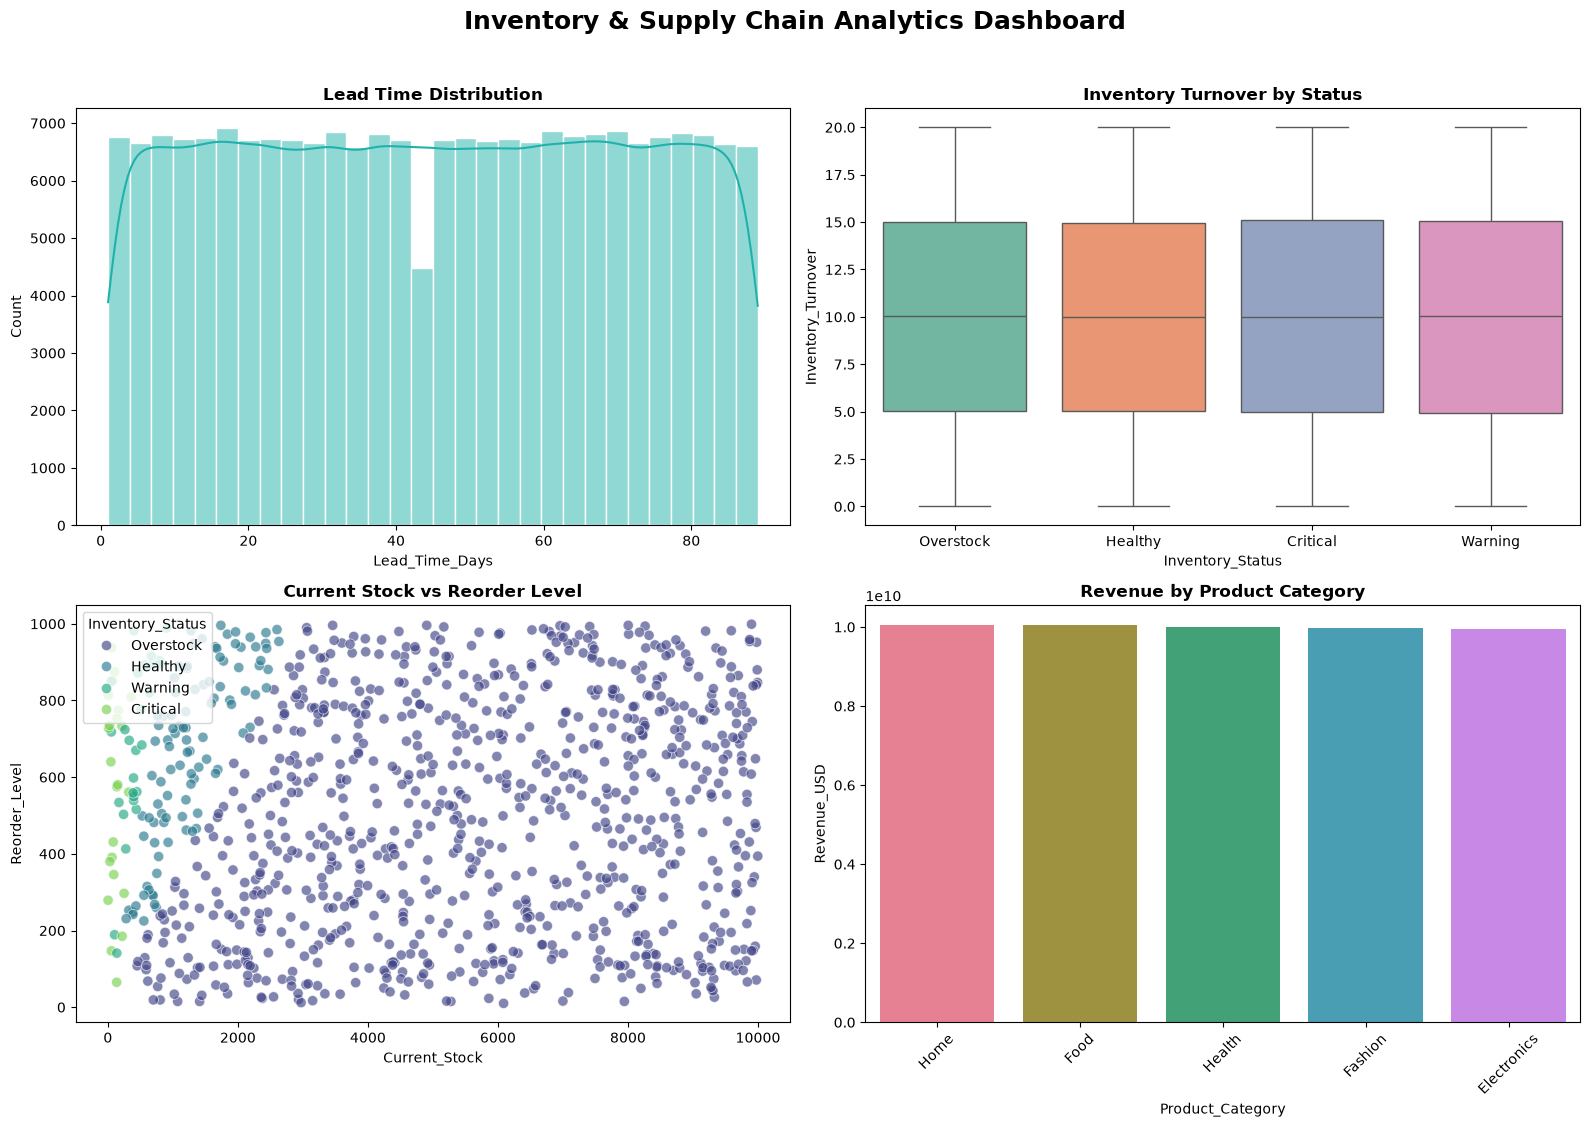

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# 1. Lead Time Distribution 
sns.histplot(
    data=df,
    x='Lead_Time_Days',
    bins=30,
    color='#20B2AA',
    edgecolor='white',
    kde=True,
    ax=axes[0, 0]
)
axes[0, 0].set_title('Lead Time Distribution', fontweight='bold')

# 2. Inventory Turnover by Status 
sns.boxplot(
    data=df,
    x='Inventory_Status',
    y='Inventory_Turnover',
    hue='Inventory_Status',
    palette='Set2',
    legend=False,
    ax=axes[0, 1]
)
axes[0, 1].set_title('Inventory Turnover by Status', fontweight='bold')

# 3. Stock vs Reorder Level 
sample_df = df.sample(n=min(1000, len(df)), random_state=42)

sns.scatterplot(
    data=sample_df,
    x='Current_Stock',
    y='Reorder_Level',
    hue='Inventory_Status',
    palette='viridis',
    alpha=0.65,
    s=55,
    ax=axes[1, 0]
)
axes[1, 0].set_title('Current Stock vs Reorder Level', fontweight='bold')

# 4. Revenue by Product Category 
revenue_by_category = (
    df.groupby('Product_Category', as_index=False)['Revenue_USD']
      .sum()
      .sort_values('Revenue_USD', ascending=False)
)

sns.barplot(
    data=revenue_by_category,
    x='Product_Category',
    y='Revenue_USD',
    hue='Product_Category',
    palette='husl',
    legend=False,
    ax=axes[1, 1]
)
axes[1, 1].set_title('Revenue by Product Category', fontweight='bold')
axes[1, 1].tick_params(axis='x', rotation=45)

# Overall formatting
fig.suptitle(
    'Inventory & Supply Chain Analytics Dashboard',
    fontsize=18,
    fontweight='bold',
    y=1.02
)


plt.tight_layout()
plt.savefig('../reports/eda_overview.png')

### 6. EXPORT PROCESSED DATA

In [21]:
df.to_csv('../data/processed/retail_supply_chain_clean.csv', index=False)
print("\n✅ Cleaned data exported successfully!")


✅ Cleaned data exported successfully!
